# 03. 베이스라인 (E0) – 학습 결과 분석 · 오류 분석 · 첫 제출

**목표**: 이후 모든 실험의 기준점을 만들고, 모델이 **무엇을 왜 틀리는지** 파악해 다음 실험의 근거로 삼는다.

| 항목 | 내용 |
|---|---|
| 모델 | YOLO11s (COCO 사전학습) |
| 입력 | 640px, Ultralytics 기본 증강 |
| 데이터 | 조합 단위 5-Fold 중 fold 0 (학습 185장 / 검증 47장) |
| 설정 | [`configs/e0_baseline.yaml`](../configs/e0_baseline.yaml) |
| 실행 | `python scripts/run_experiment.py --config configs/e0_baseline.yaml` |

학습은 스크립트로 실행하고(재현성, 로그 저장), 이 노트북은 그 결과를 불러와 분석한다.

## 0. 환경 설정

In [1]:
import os
import subprocess
import sys
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # Windows + Anaconda OpenMP 충돌 회피

REPO_URL = "https://github.com/lee-da-gyo/ai-project-01-pill-detection.git"
REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (REPO_DIR / "src" / "pilldet").exists():
    REPO_DIR = Path("/kaggle/working/repo")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
sys.path.insert(0, str(REPO_DIR / "src"))

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display
from PIL import Image

from pilldet import viz
from pilldet.config import get_paths
from pilldet.data import list_test_images, load_clean_annotations
from pilldet.evaluate import coco_map
from pilldet.predict import limit_per_image, predict_images
from pilldet.train import load_config, read_results

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

P = get_paths(REPO_DIR)
KOREAN_OK = viz.setup_korean_font()
NAME_COL = "dl_name" if KOREAN_OK else "dl_name_en"
EXP = "e0_baseline"
RUN_DIR = REPO_DIR / "runs" / EXP
EXP_DIR = P.out / "experiments" / EXP


def save_fig(fig, name: str):
    viz.save_fig(fig, P.fig, name)


def show_source(obj):
    path = Path(inspect.getsourcefile(obj)).relative_to(REPO_DIR / "src")
    display(Markdown(f"**`src/{path.as_posix()}` → `{obj.__qualname__}`**\n```python\n{inspect.getsource(obj)}```"))


cfg = load_config(REPO_DIR / "configs" / f"{EXP}.yaml")
class_map = pd.read_csv(P.out / "class_map.csv")
gt_all = load_clean_annotations(P.out / "annotations_clean.json").merge(class_map[["category_id", "dl_name", "dl_name_en"]], on="category_id")
val_files = [l.split("/")[-1] for l in (P.dataset / "fold0_val.txt").read_text().split()]
gt_val = gt_all[gt_all["file_name"].isin(val_files)]
print(yaml.safe_dump(cfg, allow_unicode=True, sort_keys=False))

name: e0_baseline
description: YOLO11s, 640px, Ultralytics 기본 증강, fold 0
model: yolo11s.pt
data: data_fold0.yaml
imgsz: 640
epochs: 100
patience: 30
batch: 16
optimizer: auto
workers: 4



## 1. 실험 코드와 실행 로그
설정 파일의 값이 그대로 Ultralytics 학습 인자로 들어간다. 실험마다 설정 파일만 바꾼다.

In [2]:
from pilldet.train import train  # noqa: E402

show_source(train)
print((P.out / "logs" / f"{EXP}.log").read_text(encoding="utf-8"))

**`src/pilldet/train.py` → `train`**
```python
def train(cfg: dict, dataset_dir: Path, runs_dir: Path, **overrides) -> Path:
    """설정대로 학습하고 실행 폴더(runs/<name>)를 반환한다."""
    from ultralytics import YOLO

    args = {**DEFAULTS, **{k: v for k, v in cfg.items() if k not in META_KEYS}, **overrides}
    model = YOLO(cfg["model"])
    model.train(data=str(Path(dataset_dir) / cfg["data"]), project=str(runs_dir), name=cfg["name"], **args)
    return Path(runs_dir) / cfg["name"]
```

2026-10-27 15:56:20 | 실험 e0_baseline: YOLO11s, 640px, Ultralytics 기본 증강, fold 0
2026-10-27 15:56:20 | 설정: {'name': 'e0_baseline', 'description': 'YOLO11s, 640px, Ultralytics 기본 증강, fold 0', 'model': 'yolo11s.pt', 'data': 'data_fold0.yaml', 'imgsz': 640, 'epochs': 100, 'patience': 30, 'batch': 16, 'optimizer': 'auto', 'workers': 4}
2026-10-27 16:02:03 | [1/4] 학습 완료 (5.7분): 최고 에포크 87 / 100 | P 0.866 R 0.822 mAP50 0.8431 mAP50-95 0.8338
2026-10-27 16:02:04 | [2/4] fold 0 COCO 평가: mAP50-95 0.8354 | mAP50 0.8471 | mAP75 0.8471
2026-10-27 16:02:04 |       AP50-95 하위 5개 클래스:
              dl_name  n_boxes  AP50_95
                 알드린정        3      0.0
    써스펜8시간이알서방정 650mg        3      0.0
        다보타민큐정 10mg/병        6      0.0
      리렉스펜정 300mg/PTP        3      0.0
자누메트엑스알서방정 100/1000mg        3      0.0
2026-10-27 16:02:23 | [3/4] 제출 파일: submissions/e0_baseline.csv {'rows': 8473, 'images_with_pred': 842, 'test_images': 842, 'rows_per_image': 10.06}  ⚠️ 제출 형식 미확인 (configs/submission.yam

## 2. 학습 곡선
손실이 줄고 val mAP가 오르다가 평탄해지는지, 과적합(train 손실↓ · val 손실↑)이 있는지 확인한다.

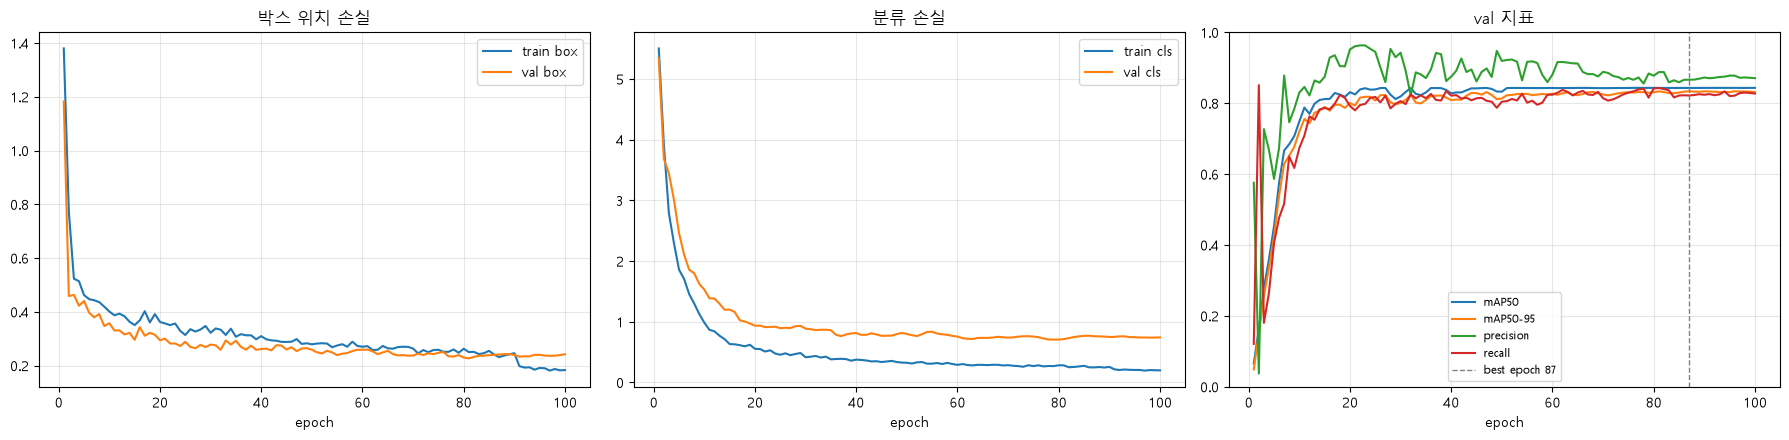

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
86,87,0.8663,0.8218,0.8431,0.8338


In [3]:
res = read_results(RUN_DIR)
best_i = res["metrics/mAP50-95(B)"].idxmax()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for col, lab in [("train/box_loss", "train box"), ("val/box_loss", "val box")]:
    axes[0].plot(res["epoch"], res[col], label=lab)
axes[0].set(title="박스 위치 손실", xlabel="epoch"); axes[0].legend()
for col, lab in [("train/cls_loss", "train cls"), ("val/cls_loss", "val cls")]:
    axes[1].plot(res["epoch"], res[col], label=lab)
axes[1].set(title="분류 손실", xlabel="epoch"); axes[1].legend()
for col, lab in [("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95"),
                 ("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall")]:
    axes[2].plot(res["epoch"], res[col], label=lab)
axes[2].axvline(res.loc[best_i, "epoch"], c="gray", ls="--", lw=1, label=f"best epoch {int(res.loc[best_i, 'epoch'])}")
axes[2].set(title="val 지표", xlabel="epoch", ylim=(0, 1)); axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
save_fig(fig, "e0_learning_curves")
plt.show()
res.loc[[best_i], ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(4)

## 3. 검증 성능 – 두 가지 평가 방식 비교
- **Ultralytics 내부 평가**: 학습 중 자동 계산
- **COCO 평가 (pycocotools)**: 직접 구현한 [`evaluate.py`](../src/pilldet/evaluate.py). 이후 2단계 모델·앙상블·TTA도 **같은 기준**으로 비교하기 위해 쓴다

두 값이 비슷해야 내 평가 코드를 믿을 수 있다.

In [4]:
exp_log = pd.read_csv(P.out / "experiments.csv")
exp_log[exp_log["name"] == EXP].T

,0
id,E0
name,e0_baseline
date,2026-10-27
description,"YOLO11s, 640px, Ultralytics 기본 증강, fold 0"
model,yolo11s.pt
imgsz,640
fold,0
epochs_run,100
best_epoch,87
precision,0.8663


## 4. 클래스별 성능 – 무엇을 못 맞히는가
EDA에서 예상한 대로 **학습 데이터가 적은 클래스**와 **학습에 아예 없는 클래스**에서 성능이 낮은지 확인한다.

검증 클래스 33개 중 학습에 없는 클래스 5개
               AP50_95   AP50
seen_in_train                
학습에 없음           0.000  0.000
학습에 있음           0.985  0.998


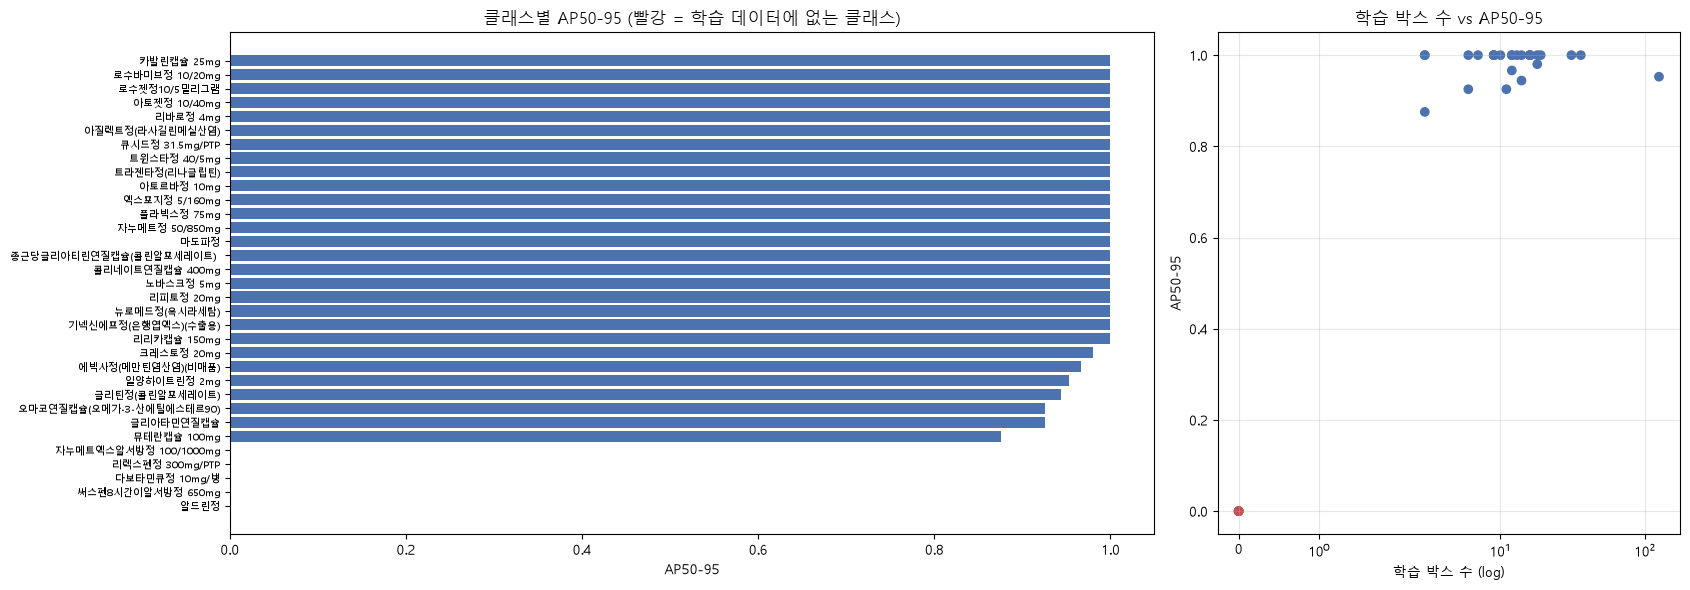

In [5]:
pc = pd.read_csv(EXP_DIR / "per_class_ap.csv")
folds = pd.read_csv(P.out / "folds.csv")
train_counts = gt_all[gt_all["file_name"].isin(folds.loc[folds["fold"] != 0, "file_name"])]["category_id"].value_counts()
pc["n_train"] = pc["category_id"].map(train_counts).fillna(0).astype(int)
pc["seen_in_train"] = pc["n_train"] > 0
print(f"검증 클래스 {len(pc)}개 중 학습에 없는 클래스 {(~pc.seen_in_train).sum()}개")
print(pc.groupby("seen_in_train")[["AP50_95", "AP50"]].mean().round(3).rename(index={True: "학습에 있음", False: "학습에 없음"}))

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [2, 1]})
s = pc.sort_values("AP50_95")
names = s["dl_name"] if KOREAN_OK else s["category_id"].astype(str)
axes[0].barh(names, s["AP50_95"], color=np.where(s["seen_in_train"], "#4C72B0", "#C44E52"))
axes[0].set(title="클래스별 AP50-95 (빨강 = 학습 데이터에 없는 클래스)", xlabel="AP50-95")
axes[0].tick_params(axis="y", labelsize=7)
axes[1].scatter(pc["n_train"], pc["AP50_95"], c=np.where(pc["seen_in_train"], "#4C72B0", "#C44E52"))
axes[1].set(xscale="symlog", title="학습 박스 수 vs AP50-95", xlabel="학습 박스 수 (log)", ylabel="AP50-95")
axes[1].grid(alpha=0.3)
plt.tight_layout()
save_fig(fig, "e0_per_class_ap")
plt.show()

## 5. 혼동 행렬과 PR 곡선 (Ultralytics)

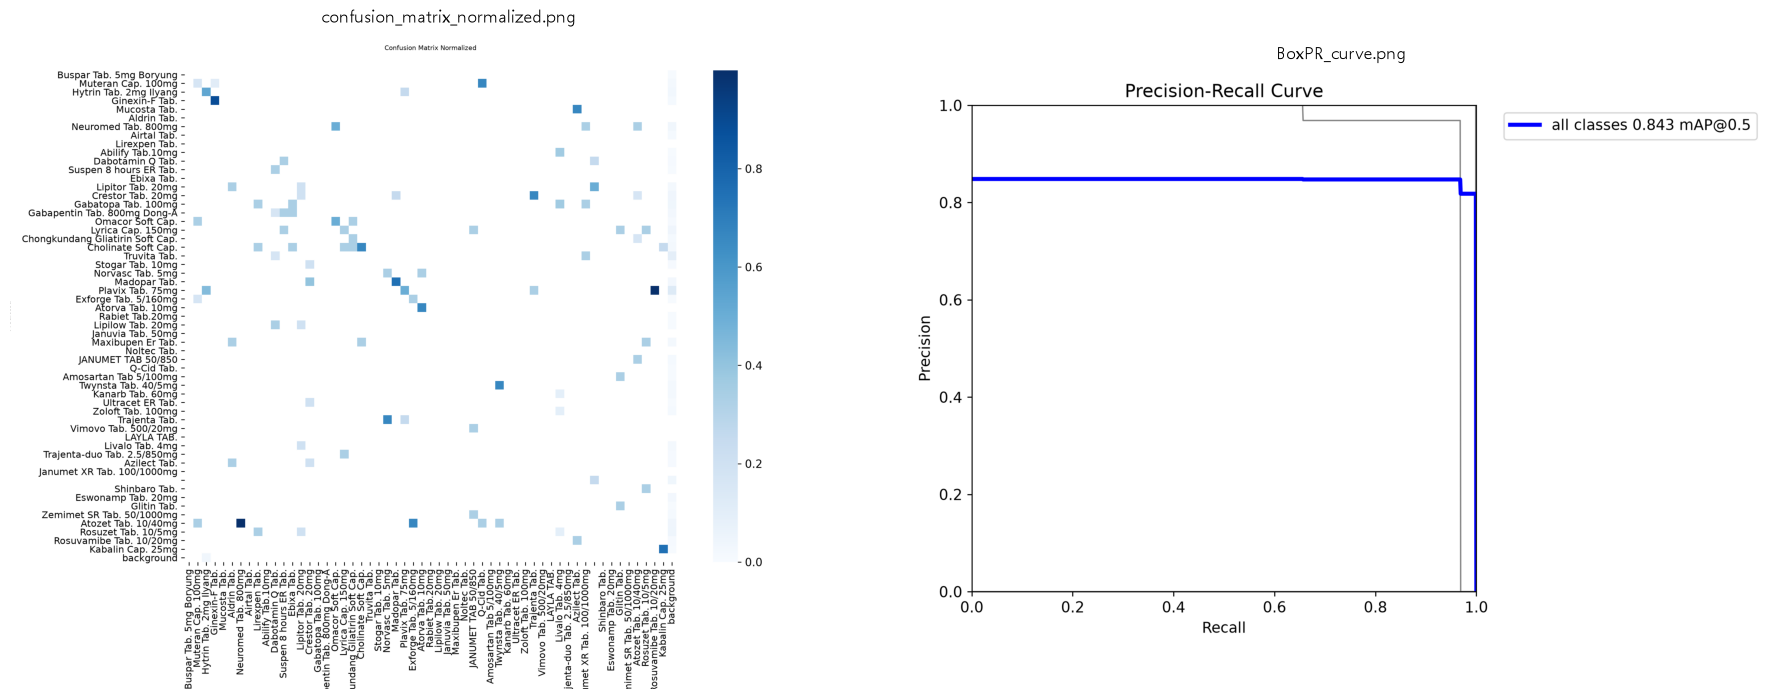

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, f in zip(axes, ["confusion_matrix_normalized.png", "BoxPR_curve.png"]):
    if (EXP_DIR / f).exists():
        ax.imshow(Image.open(EXP_DIR / f))
    ax.set_title(f)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. 인식 결과 시각화 – 정답 vs 예측
시각화에는 신뢰도 0.25 이상의 예측만 그린다 (평가에는 모든 예측을 쓴다).
이미지별로 정답 박스를 몇 개 맞혔는지 계산해 **가장 잘 맞힌 이미지와 가장 못 맞힌 이미지**를 함께 본다.

이미지별 정답 적중률 평균 0.88 / 전부 맞힌 이미지 36장 / 하나도 못 맞힌 이미지 0장


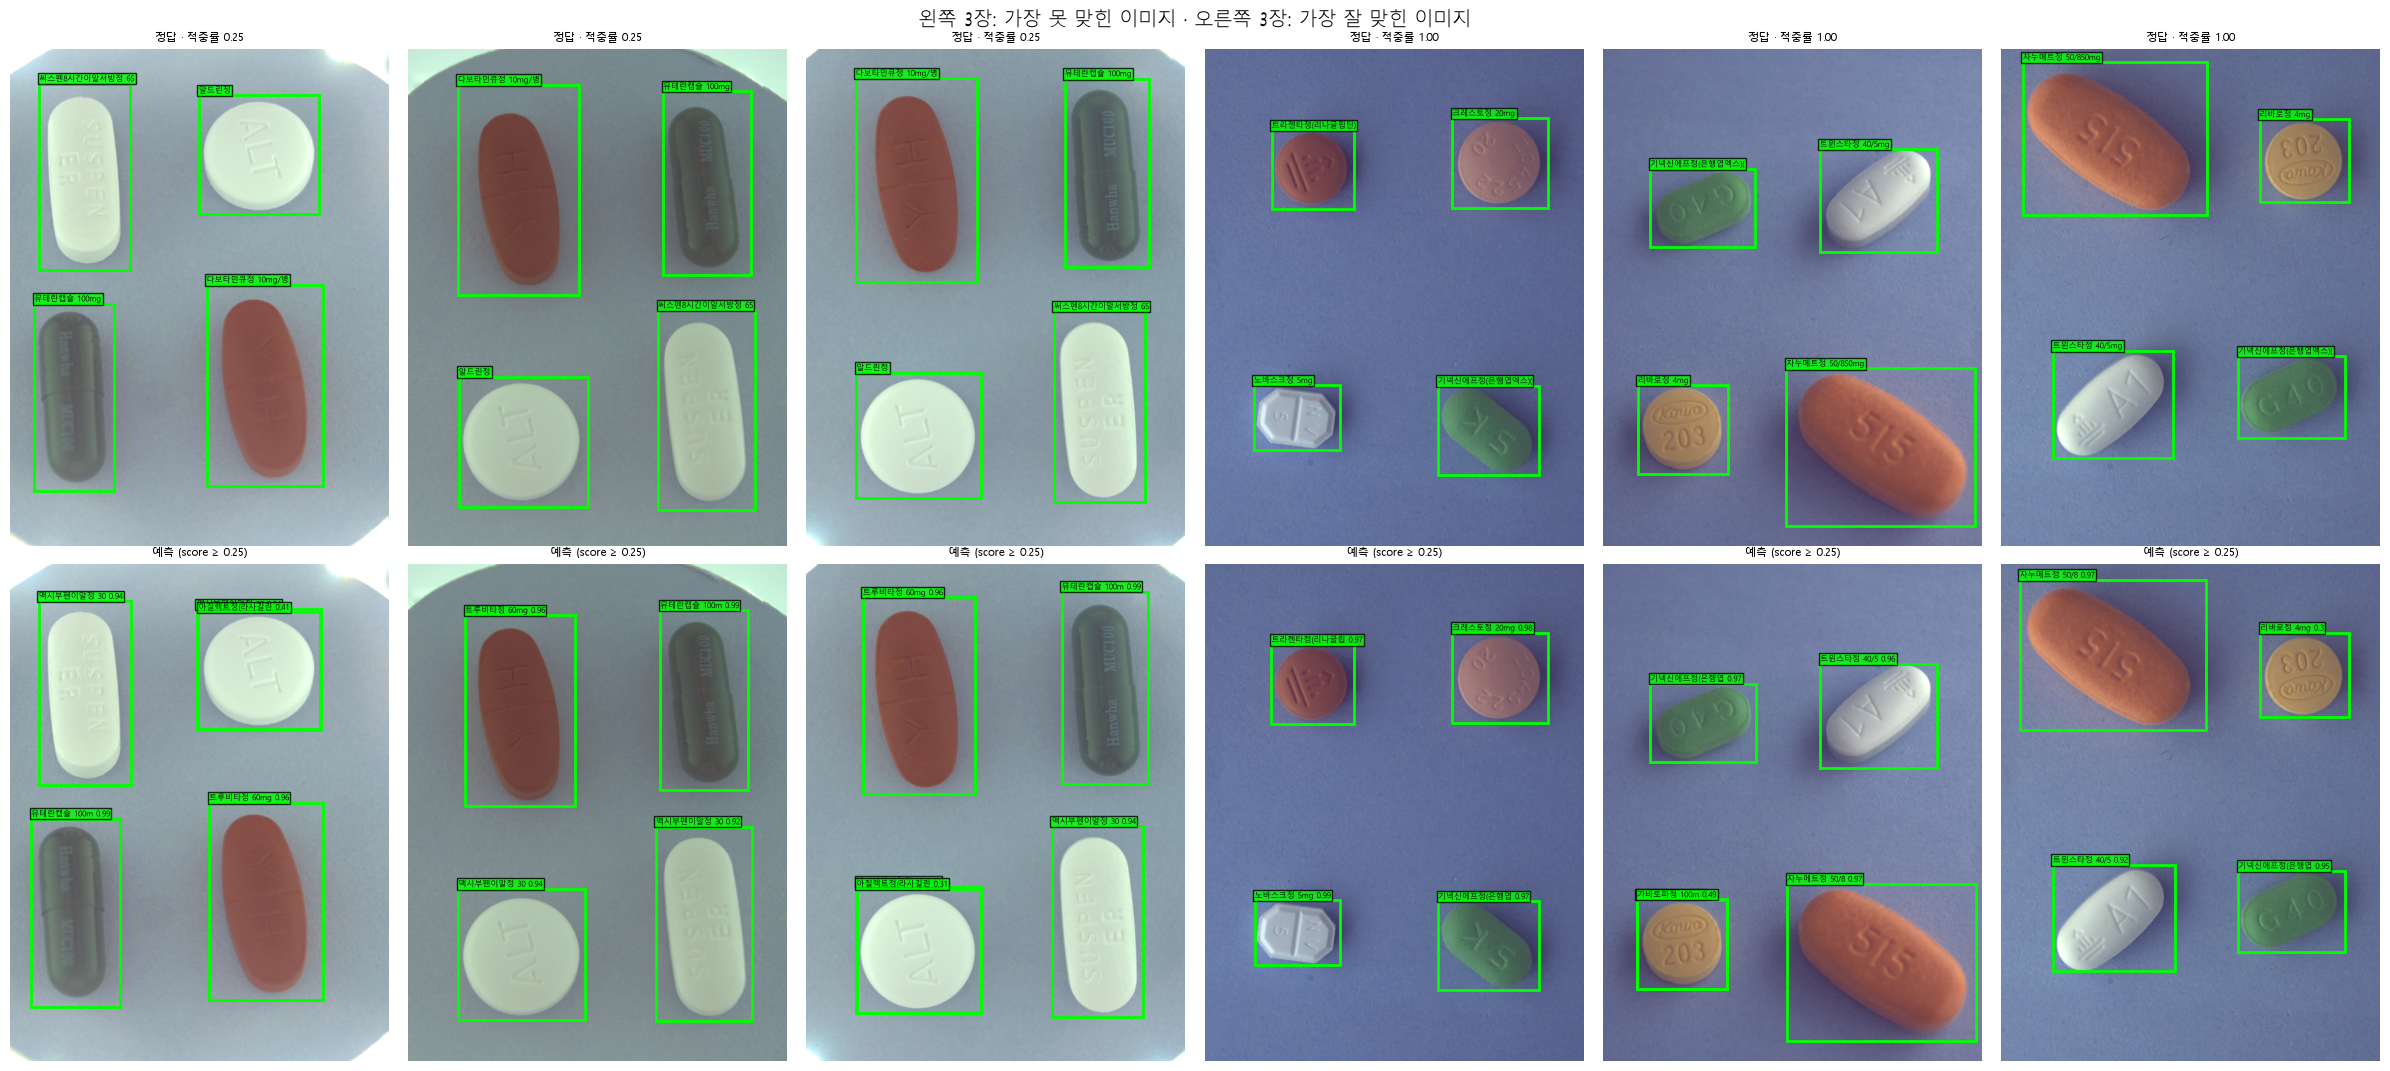

In [7]:
from pilldet.boxes import iou_matrix, to_xyxy  # noqa: E402

pred_val = pd.read_csv(EXP_DIR / "val_predictions.csv").merge(class_map[["category_id", "dl_name", "dl_name_en"]], on="category_id")
shown = pred_val[pred_val["score"] >= 0.25]


def image_hits(f):
    """정답 박스 중 같은 클래스·IoU ≥ 0.5 예측으로 맞힌 비율."""
    g, p = gt_val[gt_val["file_name"] == f], shown[shown["file_name"] == f]
    hit = 0
    for _, r in g.iterrows():
        pc_ = p[p["category_id"] == r.category_id]
        hit += int(len(pc_) and iou_matrix(to_xyxy(r.to_frame().T), to_xyxy(pc_)).max() >= 0.5)
    return hit / len(g)


hits = pd.Series({f: image_hits(f) for f in val_files}).sort_values()
print(f"이미지별 정답 적중률 평균 {hits.mean():.2f} / 전부 맞힌 이미지 {(hits == 1).sum()}장 / 하나도 못 맞힌 이미지 {(hits == 0).sum()}장")

pick = list(hits.index[:3]) + list(hits.index[-3:])
fig, axes = plt.subplots(2, 6, figsize=(24, 11))
for j, f in enumerate(pick):
    viz.draw_boxes(axes[0, j], P.train_img / f, gt_val[gt_val["file_name"] == f], NAME_COL, title=f"정답 · 적중률 {hits[f]:.2f}")
    pf = shown[shown["file_name"] == f].assign(label=lambda d: d[NAME_COL].str[:10] + " " + d["score"].round(2).astype(str))
    viz.draw_boxes(axes[1, j], P.train_img / f, pf, "label", title="예측 (score ≥ 0.25)", max_label=18)
fig.suptitle("왼쪽 3장: 가장 못 맞힌 이미지 · 오른쪽 3장: 가장 잘 맞힌 이미지", fontsize=14)
plt.tight_layout()
save_fig(fig, "e0_predictions_val")
plt.show()

## 7. 도메인 지식 후처리 미리보기
학습 없이 예측 결과만 바꿔서 효과를 본다. **이미지당 알약 최대 4개, 같은 약 중복 없음**.
mAP는 낮은 점수 예측까지 순위로 평가하므로, 개수를 줄이면 오히려 떨어질 수도 있다. 직접 확인한다.

In [8]:
show_source(limit_per_image)
rows = [{"후처리": "없음 (전체 예측)", **{k: v for k, v in coco_map(pred_val, gt_val).items() if k != "per_class"}}]
for k in (4, 10, 20):
    r = coco_map(limit_per_image(pred_val, k, unique_class=False), gt_val)
    rows.append({"후처리": f"이미지당 상위 {k}개", **{k_: v for k_, v in r.items() if k_ != "per_class"}})
r = coco_map(limit_per_image(pred_val, 4, unique_class=True), gt_val)
rows.append({"후처리": "상위 4개 + 같은 약 중복 제거", **{k_: v for k_, v in r.items() if k_ != "per_class"}})
pd.DataFrame(rows).round(4)

**`src/pilldet/predict.py` → `limit_per_image`**
```python
def limit_per_image(pred: pd.DataFrame, max_per_image: int = 4, unique_class: bool = True) -> pd.DataFrame:
    """도메인 지식 후처리: 이미지당 알약 최대 4개, 같은 약은 한 번만 나온다."""
    p = pred.sort_values("score", ascending=False)
    if unique_class:
        p = p.drop_duplicates(["file_name", "category_id"])
    return p.groupby("file_name", group_keys=False).head(max_per_image).reset_index(drop=True)
```

,후처리,mAP50_95,mAP50,mAP75
0,없음 (전체 예측),0.8354,0.8471,0.8471
1,이미지당 상위 4개,0.8222,0.8338,0.8338
2,이미지당 상위 10개,0.8354,0.8471,0.8471
3,이미지당 상위 20개,0.8354,0.8471,0.8471
4,상위 4개 + 같은 약 중복 제거,0.8222,0.8338,0.8338


## 8. 테스트 예측과 제출 파일
제출 파일은 실험 스크립트가 `submissions/e0_baseline.csv`로 만들고 형식 검사까지 마쳤다.
⚠️ 제출 컬럼 형식은 대회 페이지 확인 전 가정이다 ([`configs/submission.yaml`](../configs/submission.yaml)).

제출 파일 e0_baseline.csv: 8,473행 / 이미지 842장 / 이미지당 평균 10.1개 예측


,annotation_id,image_id,category_id,bbox_x,bbox_y,bbox_w,bbox_h,score
0,1,1,16551,558.48,71.30,389.57,405.33,0.98538
1,2,1,27926,599.91,671.91,258.15,483.45,0.97349
2,3,1,1900,157.58,252.17,203.12,124.33,0.96242
3,4,1,29345,172.06,740.68,183.15,294.71,0.86927
4,5,1,27733,559.31,67.86,392.34,407.87,0.04503


WARNING Empty class name string(s) at class indices [47] will display as blank labels.


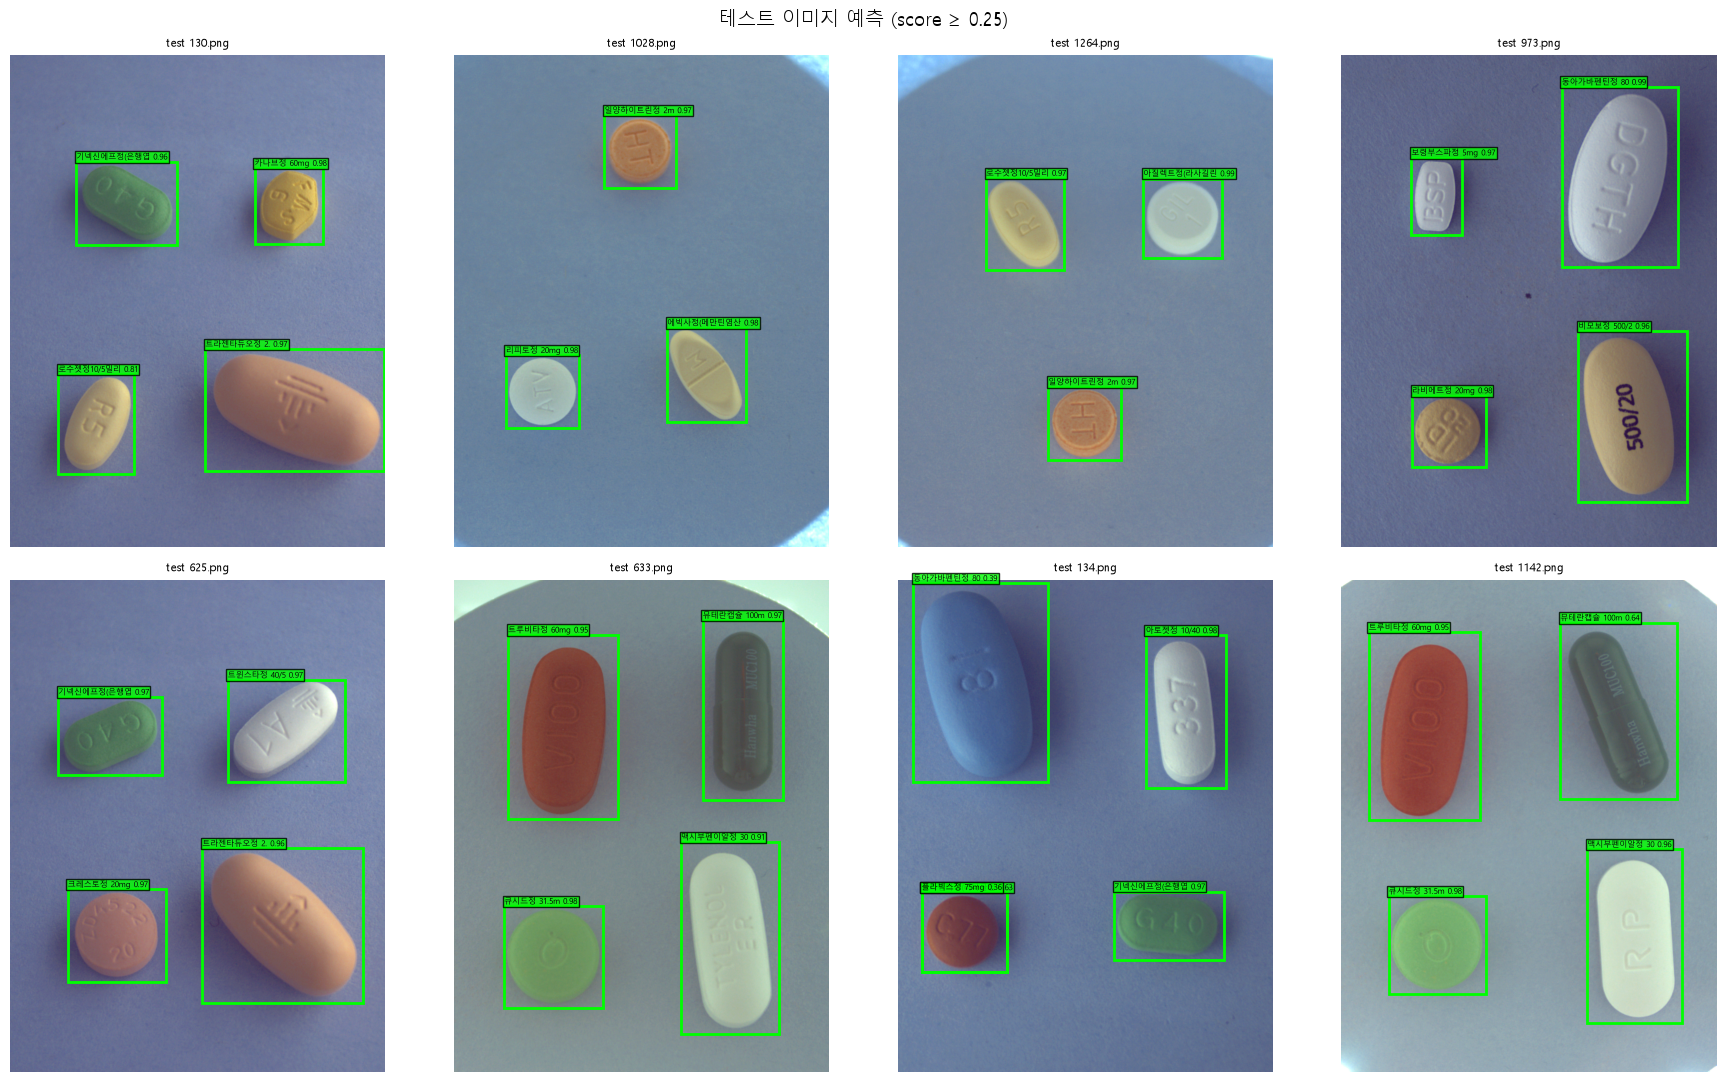

In [9]:
sub_path = REPO_DIR / "submissions" / f"{EXP}.csv"
sub = pd.read_csv(sub_path)
print(f"제출 파일 {sub_path.name}: {len(sub):,}행 / 이미지 {sub['image_id'].nunique()}장 / 이미지당 평균 {len(sub) / sub['image_id'].nunique():.1f}개 예측")
display(sub.head())

test_paths = list_test_images(P.test_img)
rng = np.random.default_rng(42)
pick = [test_paths[i] for i in rng.choice(len(test_paths), 8, replace=False)]
pt = predict_images(RUN_DIR / "weights" / "best.pt", pick, class_map, imgsz=cfg["imgsz"], conf=0.25)
pt = pt.merge(class_map[["category_id", "dl_name", "dl_name_en"]], on="category_id")
pt["label"] = pt[NAME_COL].str[:10] + " " + pt["score"].round(2).astype(str)
fig, axes = plt.subplots(2, 4, figsize=(18, 11))
for ax, p in zip(axes.flat, pick):
    viz.draw_boxes(ax, p, pt[pt["file_name"] == p.name], "label", title=f"test {p.name}", max_label=18)
fig.suptitle("테스트 이미지 예측 (score ≥ 0.25)", fontsize=14)
plt.tight_layout()
save_fig(fig, "e0_predictions_test")
plt.show()

## 9. 결론과 다음 실험

### 결과 요약
| 항목 | 결과 | 해석 |
|---|---|---|
| **검증 mAP50-95** | COCO **0.835** · Ultralytics 0.834 | 두 평가 방식이 0.002 이내로 일치 → 직접 구현한 평가 코드를 신뢰할 수 있다 |
| 학습 곡선 | 박스 손실은 train·val이 함께 감소, 87 에포크에서 최고 | 위치 학습에는 과적합이 없다. 90 에포크 이후의 급감은 마지막 10 에포크에 모자이크 증강을 끄는 설정 때문 |
| val 분류 손실 | 0.75 근처에서 더 내려가지 않음 | 아래의 "처음 보는 약" 때문 |
| **학습에 있는 약 (28종)** | AP50-95 **0.985** | 본 적 있는 약은 거의 완벽하게 찾고 맞힌다 |
| **학습에 없는 약 (5종)** | AP50-95 **0.000** | 점수 손실의 **전부**가 여기서 나온다 |
| 이미지별 적중률 | 평균 0.88, 하나도 못 맞힌 이미지 0장 | 모든 이미지에서 위치는 정확하다 |

### 핵심 발견: 오류는 "위치"가 아니라 "처음 보는 약의 이름"이다
못 맞힌 이미지를 보면 박스 위치는 모두 맞다. 학습에 없던 약을 **생김새가 비슷한 아는 약으로 높은 확신(0.9 이상)으로** 예측한다
(예: 붉은 장방형 `다보타민큐정` → `트루비타정`, 흰 원형 `알드린정` → `아질렉트정`). 모델은 모르는 클래스를 예측할 수 없으므로 이는 open-set 문제다.

- 최종 제출 모델은 **232장 전체**로 학습해 56종을 모두 본다. 따라서 fold 검증의 "처음 보는 약" 감점은 테스트에서는 생기지 않는다(테스트가 같은 56종이라면).
- → 실험 비교에는 **학습에 있는 클래스만의 mAP(`seen_mAP50_95`)** 를 함께 기록한다.
- → 실제 위험은 **샘플이 3장뿐인 희귀 약**이 테스트의 다른 조합·배치에서도 맞는가이다. 이를 위한 증강(Copy-Paste)과 분류기 강화가 다음 과제다.

### 가설 검증: 이미지당 상위 4개 제한
도메인 지식(이미지당 알약 최대 4개)으로 예측을 4개로 줄이면 mAP50-95가 **0.835 → 0.822로 떨어졌다**. mAP는 점수 순위로 평가하므로, 낮은 점수의 2·3순위 후보가 정답일 때 점수를 얻는다.
→ **가설 기각**: 제출 파일에는 모든 예측을 유지한다. (시연 앱처럼 사람이 보는 결과에는 상위 4개 + 중복 제거를 쓴다.)

### 다음 실험
| ID | 실험 | 근거 |
|---|---|---|
| E1 | 입력 해상도 960 / 1280 | 비슷한 약은 각인으로 구분된다 → 해상도가 클수록 유리할 것 |
| E2 | 모델 크기 n / m, 최신 구조 YOLO26s | 데이터가 적어 큰 모델은 과적합될 수 있다 → 직접 비교 |
| E3 | 증강 (회전·뒤집기·색, Copy-Paste) | 희귀 약의 다양한 배치·맥락을 만든다 |
| – | **첫 Kaggle 제출** | 테스트가 학습과 같은 56종이라면 Kaggle 점수는 fold 검증(0.835)보다 높게 나올 것이다 → 확인 |
